# 4. Evaluation

# Accuracy and dummy model

In this lesson we look at accuracy, the simplest evaluation metric: the fraction of predictions the model got right. We check whether 0.5 is the best decision threshold for our churn model, and then compare it against a dummy model that predicts nobody will churn.

## Setup

Rebuild the data split and the model from lesson 3. With the same `random_state=1`, `y_train`, `y_val` and `y_test` are identical to the ones in [classification.ipynb](../lesson-03/classification.ipynb).

In [1]:
import pandas as pd
import numpy as np

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv('../data/data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [4]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender', 'seniorcitizen', 'partner', 'dependents',
    'phoneservice', 'multiplelines', 'internetservice',
    'onlinesecurity', 'onlinebackup', 'deviceprotection',
    'techsupport', 'streamingtv', 'streamingmovies',
    'contract', 'paperlessbilling', 'paymentmethod',
]

In [5]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [6]:
model = LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)

/Users/ifabela/Documents/iocode/DataTalks_club/ml-course-datatalksclub/.venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [7]:
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)

# 4.2 Accuracy

Accuracy measures the fraction of correct predictions: the number of correct predictions divided by the total number of predictions.



<p align="center">
  <img src="./images/02-accuracy-02-accuracy-example-crisp.jpg" alt="Difference and risk ratio: two ways of comparing a group churn rate with the global one" width="520">
</p>

Our validation set has 1409 customers:

In [8]:
len(y_val)

1409

This gives `1409`. With the decision threshold at 0.5, the model made the right call for 1132 of them:


In [9]:
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

This gives `0.8034066713981547`. Indeed, 1132 / 1409 is 0.8034 - about 80% of the predictions match the actual outcomes.

Scikit-learn has this computation built in as `accuracy_score`:

In [10]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

This gives the same `0.8034066713981547`.

## Checking different thresholds

The 0.5 threshold was a guess. Nothing forces us to use it: the model outputs a probability, and we can announce churn for any cutoff we like. Let's check all thresholds from 0 to 1 in steps of 0.05 and see which one gives the best accuracy:


In [11]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.509
0.10 0.591
0.15 0.666
0.20 0.710
0.25 0.739
0.30 0.760
0.35 0.772
0.40 0.785
0.45 0.793
0.50 0.803
0.55 0.801
0.60 0.795
0.65 0.786
0.70 0.766
0.75 0.744
0.80 0.735
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


Plotted, the accuracy rises quickly, peaks around 0.5, and then slowly declines before flattening out:


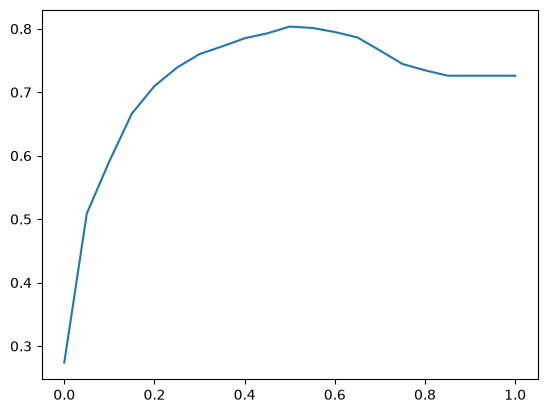

In [12]:
import matplotlib.pyplot as plt

plt.plot(thresholds, scores)

In [13]:
accuracy_score(y_val, churn_decision)

0.8034066713981547

So for this problem the best decision cutoff is indeed 0.5, with 80% accuracy. That was a lucky guess - but it didn't have to be. On other problems the best threshold is often different from 0.5, and this simple loop is how you find it.


## The dummy model

Here comes the uncomfortable check. What if we don't use a model at all, and simply predict that no customer will ever churn? That is the same as setting the threshold to 1.0: no prediction can reach it, so every customer is predicted as "no churn":


In [14]:
from collections import Counter

Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

The output confirms it - every single prediction is `False`:

```text
Counter({False: 1409})
```

What accuracy does this dummy model get? The answer is the fraction of customers who did not churn:

# 4.3 Confusion table

Accuracy collapses all predictions into a single number, so it cannot tell us which kinds of mistakes the model makes. In this lesson we look at the confusion table: a way of measuring the different types of errors and correct decisions a binary classifier can make, arranged in one table.


## Four outcomes of a prediction

For churn prediction, each customer in the validation set falls into one of four categories, depending on what we predicted and what actually happened:

| Prediction | Actual | Name |
|------------|--------|------|
| Customer will churn (positive) | Churned | True Positive (TP) |
| Customer will churn (positive) | Did not churn | False Positive (FP) |
| Customer will not churn (negative) | Churned | False Negative (FN) |
| Customer will not churn (negative) | Did not churn | True Negative (TN) |

Reading the names: "positive"/"negative" is what we predicted, "true"/"false" is whether that prediction was correct. A false positive is a customer we sent a promotional email to, but who was never going to leave. A false negative is a customer who left without us ever flagging them - often the more costly mistake.
<p align="center">
  <img src="./images/03-confusion-table-01-four-outcomes-crisp.jpg" alt="The four outcomes of a churn prediction: true negative, false negative, false positive and true positive" width="640">
</p>


<p align="center">
    <img src="./images/churn_confusion_matrix_dark.svg" width="700">
</p>

### Computing the counts

To put every customer into one of the four cells, we compare the actual values with the predictions at threshold 0.5:

In [15]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [16]:
actual_positive[:5], actual_negative[:5]

(array([False, False, False,  True, False]),
 array([ True,  True,  True, False,  True]))

In [17]:
predict_positive[:5]

array([False, False, False,  True, False])

In [18]:
predict_negative[:5]

array([ True,  True,  True, False,  True])

Each cell is the number of customers where the two conditions hold at the same time. The `&` operator is the element-wise logical AND:


In [19]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

In [20]:
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [21]:
[fp, fn] , [tp,tn]

([np.int64(101), np.int64(176)], [np.int64(210), np.int64(922)])

For our model this gives tp = 210, tn = 922, fp = 101 and fn = 176 - and indeed 210 + 922 + 101 + 176 = 1409, all customers accounted for.


<p align="center">
  <img src="./images/03-confusion-table-04-confusion-counts-crisp.jpg" alt="The four groups in the validation set: 922 true negatives, 101 false positives, 176 false negatives and 210 true positives" width="720">
</p>

## The table

Arranging the four numbers with predictions in columns and actual values in rows gives the confusion table:

<p align="center">
    <img src="./images/churn_confusion_matrix_table_dark.svg" width="620">
</p>

In [22]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[922, 101],
       [176, 210]])


|                | Predicted negative | Predicted positive |
|----------------|--------------------|--------------------|
| Actual negative | TN = 922          | FP = 101           |
| Actual positive | FN = 176          | TP = 210           |

Dividing each cell by the total turns the counts into fractions of the whole validation set:


In [23]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

So 65% of all customers are true negatives, 7% false positives, 12% false negatives and 15% true positives.

Accuracy fits right back in: it is the sum of the diagonal - the correct decisions TN and TP - divided by the total. Here (922 + 210) / 1409 = 0.8034, the same 80% as before. What the table adds is the split of the remaining 20% into 7% of false positives and 12% of false negatives - two errors with very different business costs.

## Notes
<details>
<summary>Written by the community</summary>

Confusion table is a way of measuring different types of errors and correct decisions that binary classifiers can make. Considering this information, it is possible to evaluate the quality of the model by different strategies.

When comes to a prediction of an LR model, each falls into one of four different categories:

* Prediction is that the customer WILL churn. This is known as the **Positive class**
  * And Customer actually churned - Known as a **True Positive (TP)**
  * But Customer actually did not churn - Known as a **False Positive (FP)**
* Prediction is that the customer WILL NOT churn' - This is known as the **Negative class**
  * Customer did not churn - **True Negative (TN)**
  * Customer churned - **False Negative (FN)**

`Confusion Table` is a way to summarize the above results in a tabular format, as shown below:

<table>
  <tr>
    <th></th>
    <th></th>
    <th colspan="2" style="text-align: center;">Predictions</th>
  </tr>
  <tr>
    <td></td>
    <td></td>
    <td>Negative</td>
    <td>Positive</td>
  </tr>
  <tr>
    <td rowspan="2">Actual</td>
    <td>Negative</td>
    <td style="text-align: center;">TN</td>
    <td style="text-align: center;">FP</td>
  </tr>
  <tr>
    <td>Positive</td>
    <td style="text-align: center;">FN</td>
    <td style="text-align: center;">TP</td>
  </tr>
</table>

The **accuracy** corresponds to the sum of TN and TP divided by the total of observations.

<table>
   <tr>
      <td>⚠️</td>
      <td>
         The notes are written by the community. <br>
         If you see an error here, please create a PR with a fix.
      </td>
   </tr>
</table>

</details>


# 4.4 Precision and Recall

The confusion table showed us our model makes two very different kinds of mistakes. Precision and recall are the two metrics that look at each kind separately: they both focus on the positive class - the customers we want to catch - and they both see problems that accuracy hides.


## Precision

Precision tells us the fraction of positive predictions that are correct. It looks only at the customers we predicted to churn - the positive column of the confusion table (TP and FP):

<p align="center">

<code>
    P = TP / (TP + FP)
</code>
</p>

<p align="center">
    <img src="./images/precision_diagram_dark.svg" width="610">
</p>

For our model:

In [24]:
p = tp / (tp + fp)
p

np.float64(0.6752411575562701)

This gives `0.6752411575562701` - precision of about 67%.

In the terms of the churn problem: we send a retention email to everyone predicted to churn. That is 210 + 101 = 311 people, but only 210 of them (the true positives) were actually going to leave. The other 101 - about a third of all emails - go to customers who were never at risk, and the discount we send them is wasted.


## Recall

Recall measures the fraction of actual positive instances that we identified correctly. It looks at the customers who really churned - the positive row of the confusion table (TP and FN):

```text
R = TP / (TP + FN)
```

For our model:

In [25]:
r = tp / (tp + fn)
r

np.float64(0.5440414507772021)

This gives `0.5440414507772021` - recall of about 54%.

Again in the terms of the problem: 210 + 176 = 386 customers actually churned, but our model flagged only 210 of them. For the remaining 176 - about 46% of all churners - we did nothing: no email, no discount, and the customer left. This is the part accuracy never showed us.

<p align="center">
  <img src="./images/04-precision-recall-05-recall-example-crisp.jpg" alt="A recall example: three of the four actual churners are flagged, one is missed" width="520">
</p>

## Why not just accuracy

Recall what accuracy said: 80% correct, only 4 points above the dummy model. Precision and recall explain where the model actually stands: of the customers we alert, two thirds are real (precision 67%), but we miss almost half of the customers who leave (recall 54%).

<p align="center">
  <img src="./images/04-precision-recall-06-precision-recall-table-crisp.jpg" alt="Precision looks at the predicted-positive column, recall at the actual-positive row of the confusion table" width="520">
</p>

These numbers reflect the errors of our model that accuracy did not notice because of class imbalance: churners are only 27% of the data, so the 12% of false negatives barely move the accuracy number, yet they are half of all the customers we care about. When the classes are imbalanced - churn, fraud, medical diagnosis - precision and recall are the metrics to look at.


<p align="center">
  <img src="./images/accuracy_precision_recall_targets_dark.svg" alt="Targets comparing high and low precision with high and low accuracy, plus the formulas for accuracy, precision and recall" width="520">
</p>

## Notes

<details>

**Precision** tell us the fraction of positive predictions that are correct. It takes into account only the **positive class** (TP and FP - second column of the confusion matrix), as is stated in the following formula:


$$P = \cfrac{TP}{TP + FP}$$


**Recall** measures the fraction of correctly identified positive instances. It considers parts of the **positive and negative classes** (TP and FN - second row of confusion table). The formula of this metric is presented below: 


$$R = \cfrac{TP}{TP + FN}$$


 In this problem, the precision and recall values were 67% and 54% respectively. So, these measures reflect some errors of our model that accuracy did not notice due to the **class imbalance**. 

**MNEMONICS:**

- Precision : From the `pre`dicted positives, how many we predicted right. See how the word `pre`cision is similar to the word `pre`diction? 

- Recall : From the `real` positives, how many we predicted right. See how the word `re`c`al`l is similar to the word `real`?

</details>

# 4.5 ROC Curves



## TPR and FPR (True Positive Rate & False Positive Rate)

The ROC curve is built from two rates derived from the confusion table, and is a visual representation of model performance across all thresholds. It's a way to evaluate binary classification models.

<p align="center">ROC = Receiver Operating Characteristics</p>

We are interested in the **True Positive Rate** and **False Positive Rate**.

The true positive rate (TPR) is the fraction of actual positives we identified correctly - it is the same thing as recall: TP divided by all positive observations (TP and FN, the second row of the table). This is the metric we want to maximize.

**True Positive Rate** (recall) is the fraction of true positives over all actual positives (first column of the confusion matrix):

$$
TPR = \frac {TP} {TP + FN}
$$

**False Positive Rate** is the fraction of false positives over all negatives (first row of the confusion matrix):

$$
FPR = \frac {FP} {FP + TN}
$$


<p align="center">
  <img src="./images/fpr_tpr_confusion_dark.svg" alt="Confusion table with FPR = FP / (TN + FP) to minimize over actual negatives and TPR = TP / (FN + TP) to maximize over actual positives" width="620">
</p>



total number of positives = predicted positive, is positive (TP) + predicted negative, is positive (FN)

In [26]:
tpr =  tp / (tp + fn)
tpr

np.float64(0.5440414507772021)

total number of negatives = predicted negative, is negative (TN) + predicted positives, is negative (FP)

In [27]:
fpr = fp / (fp + tn)
fpr

np.float64(0.09872922776148582)

TPR is `0.5440414507772021` (the same 54% as recall) and FPR is `0.09872922776148582` - we bother 10% of the customers who were never going to churn.


## TPR and FPR at all thresholds

These two numbers describe the model at one threshold. Now let's compute them for many thresholds. We loop over 101 thresholds from 0 to 1 and record tp, fp, fn and tn for each:


In [28]:
scores = []

# Creating an array of evenly-spaced probabilities from 0 to 1 (aka 0, 0.1, 0.2, ..., 0.99, 1)
thresholds = np.linspace(0, 1, 101)

# Printing true positives & negatives, false positives & negatives for each rate 
for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    # List of tuples is created per threshold
    scores.append((t, tp, fp, fn, tn))

Plotting both rates against the threshold shows how the trade-off shifts: as the threshold grows, we flag fewer customers, so both the true positive rate and the false positive rate fall:


In [29]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn' ]
df_scores = pd.DataFrame(scores, columns=columns)

In [30]:
df_scores[::10]

,threshold,tp,fp,fn,tn
0,0.0,386,1023,0,0
10,0.1,366,556,20,467
20,0.2,333,356,53,667
30,0.3,284,236,102,787
40,0.4,249,166,137,857
50,0.5,210,101,176,922
60,0.6,150,53,236,970
70,0.7,76,20,310,1003
80,0.8,13,1,373,1022
90,0.9,0,0,386,1023


In [31]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [32]:
df_scores[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,366,556,20,467,0.948187,0.543500
20,0.2,333,356,53,667,0.862694,0.347996
30,0.3,284,236,102,787,0.735751,0.230694
40,0.4,249,166,137,857,0.645078,0.162268
50,0.5,210,101,176,922,0.544041,0.098729
60,0.6,150,53,236,970,0.388601,0.051808
70,0.7,76,20,310,1003,0.196891,0.019550
80,0.8,13,1,373,1022,0.033679,0.000978
90,0.9,0,0,386,1023,0.000000,0.000000


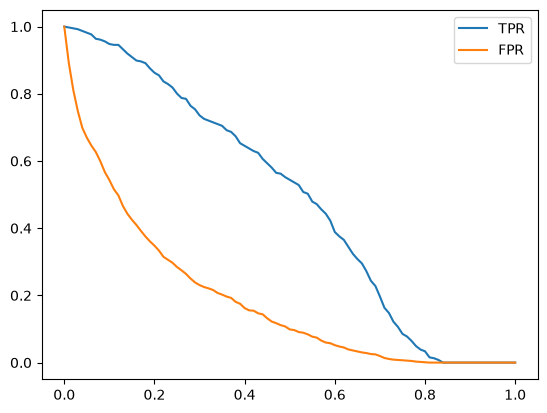

In [33]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

The ROC plot gives us an idea about how many of each type of mistake the model makes. However we have no baseline to compare it to. Therefore we will make a random model next which basically flips a coin and see how well it performs.

1. At threshold 0, we do predict everyone that churns as positive, so the TPR = 1. But at the same time, we do not predict anyone as negative. Therefore, the true negative = 0, and FPR = 1 since FP / FP + TN is effectively FP/FP which equals 1.
2. Both TPR and FPR goes down when we increase the threshold, but the FPR decreases at a faster rate. We do want the FPR to decrease faster!

## Random model
To read this curve we need points of reference. The first one: a model that outputs random scores. We generate a uniform random score for every customer:

In [34]:
# Plucking numbers from a straight line distribution, size should be the same as validation data 
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [35]:
# Default threshold of 0.5 
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

Its accuracy at threshold 0.5 is `0.5017743080198722` - a coin flip, as expected. Computing the TPR/FPR table for these random scores (with the same loop, wrapped in a reusable function `tpr_fpr_dataframe`) and plotting gives two almost straight lines going down together:


In [36]:
# Using the previous function to create 
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    
    return df_scores

In [37]:
# We use y_random for the prediction values in this case
df_rand = tpr_fpr_dataframe(y_val, y_rand)

In [38]:
df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


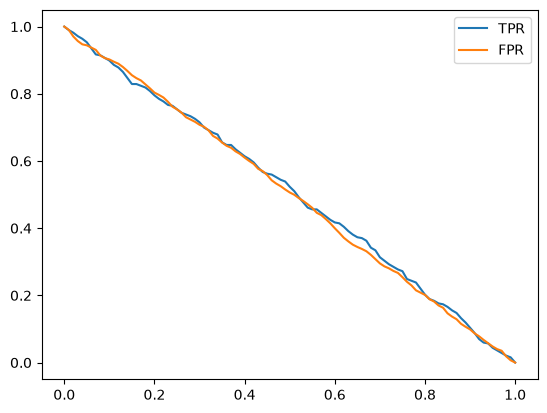

In [39]:
plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')
plt.legend()

For the random model, at any threshold the fraction of positives we catch is the same as the fraction of negatives we bother - it cannot tell the two groups apart.

## Ideal Model

The second reference: an ideal model that ranks all customers perfectly - every churner gets a higher score than every non-churner. We build it by hand: sort the customers so all 1023 negatives come first, then all 386 positives, and give them scores evenly spread from 0 to 1:


In [40]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [41]:
# Repeating the 0 and 1 values according to the num_neg and num_pos 
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal

# We create a ideal prediction dataset with values corresponding to 0 or 1 with regards to the threshold
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [42]:
# Rate of non-churning, aka the threshold which we will set this model with 
1 - y_val.mean()

np.float64(0.7260468417317246)

Where should we put the threshold? At the fraction of negatives, 0.726 - the ideal score that separates the two groups:


This gives `1.0` - perfect predictions, as an ideal model should. Its TPR and FPR vs threshold:

In [43]:
((y_ideal_pred >= 0.726) == y_ideal).mean()

np.float64(1.0)

In [44]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

This is how our model looks like but this model doesn't exist.

In [45]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

In [46]:
df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


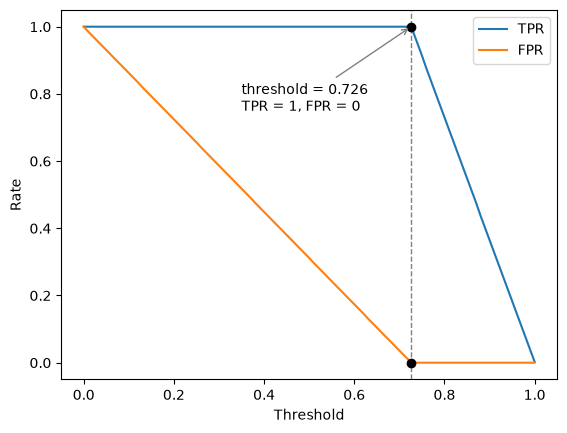

In [47]:
t = round(1 - y_val.mean(), 3)  # 0.726

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')

plt.axvline(t, color='gray', linestyle='--', linewidth=1)
plt.scatter([t, t], [1, 0], color='black', zorder=3)

plt.annotate(f'threshold = {t}\nTPR = 1, FPR = 0',
             xy=(t, 1), xytext=(0.35, 0.75),
             arrowprops=dict(arrowstyle='->', color='gray'))

plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.legend()
plt.show()


The ideal TPR stays at 1.0 for every threshold below 0.726 - it catches all churners while they all score higher than any non-churner - and only then drops. The ideal FPR falls to 0 at that same point.


## Putting everything together
Using all the models in a plot

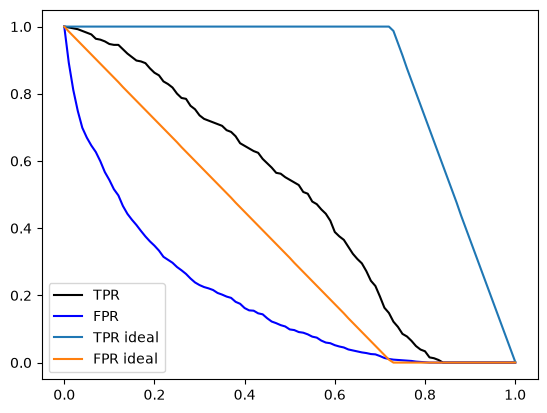

In [48]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

# plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR random', color='grey')
# plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR random', color='grey')

plt.legend()

## The ROC curve

The ROC curve itself plots TPR against FPR - not against the threshold. Each point on the curve is the model operating at one threshold: the bottom-left corner is a conservative model (flag almost nobody, bother almost nobody), the top-right corner flags everybody. We plot our model against the random one, which becomes the diagonal line from (0, 0) to (1, 1):

We can see that both our TPR and FPR are rather far from the ideal rates themselves. Plotting against the threshold isn't always very intuitive, but what we can do is to plot FPR against TPR, also known as a ROC curve.

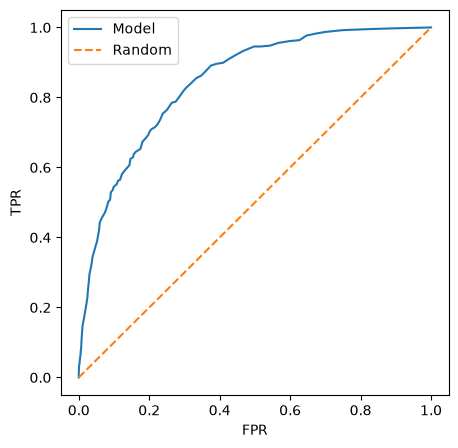

In [49]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.fpr, df_scores.tpr, label='Model')

#Uncomment if you want to see the random plot
#plt.plot(df_rand.fpr, df_rand.tpr, label = 'random')

# The random plot, simplified as ultiamtely it's still quite linear despite some fluctuations
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

# Uncomment this if you want to see the ideal plot
# We ultimately want our model plot to be as close to the ideal plot as possible
#plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

The lesson to take away: the closer the curve hugs the top-left corner - high true positive rate at a low false positive rate - the better the model. A curve sitting on the diagonal belongs to a random model.


## ROC curves with scikit-learn

We don't have to compute the table by hand: `roc_curve` from scikit-learn does it in one call, returning the false positive rates, the true positive rates and the thresholds:

For a guideline:

- The closer a model is to the ideal model, the better it is
- If it's closer to the random model but still above the model, it is not very good.
- Your model should NOT go below the random model itself, that means that there is something wrong.

In [50]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

The resulting curve is the same:

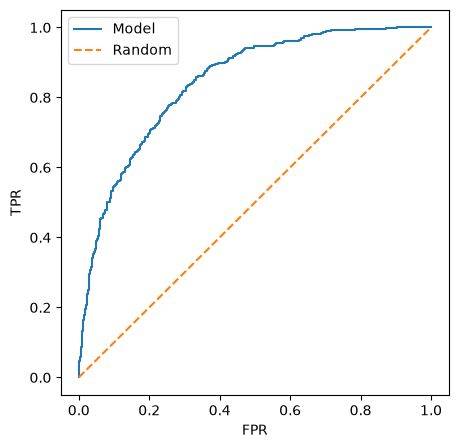

In [51]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

What kind of information do we get from this curve - and how do we boil it down to a single number? That is the ROC AUC metric, the topic of the next lesson.


## Materials

[Slides](https://www.slideshare.net/AlexeyGrigorev/ml-zoomcamp-4-evaluation-metrics-for-classification)

- [Continuation of this lesson](https://www.youtube.com/watch?v=B5PATo1J6yw&list=PL3MmuxUbc_hIhxl5Ji8t4O6lPAOpHaCLR)

## Notes

ROC stands for Receiver Operating Characteristic, and this idea was applied during the Second World War for evaluating the strength of radio detectors. This measure considers **False Positive Rate** (FPR) and **True Postive Rate** (TPR), which are derived from the values of the confusion matrix.

**FPR** is the fraction of false positives (FP) divided by the total number of negatives (FP and TN - the first row of confusion matrix), and we want to `minimize` it. The formula of FPR is the following: 

<p align="center">

$$FPR = \large \frac{FP}{TN + FP}$$
</p>

In the other hand, **TPR** or **Recall** is the fraction of true positives (TP) divided by the total number of positives (FN and TP - second row of confusion table), and we want to `maximize` this metric. The formula of this measure is presented below: 

<p align="center">

$$TPR =\large \frac{TP}{TP + FN}$$
</p>

ROC curves consider Recall and FPR under all the possible thresholds. If the threshold is 0 or 1, the FPR and Recall scores are the opposite of the threshold (1 and 0 respectively), but they have different meanings, as we explained before. 

We need to compare the ROC curves against a point of reference to evaluate its performance, so the corresponding curves of random and ideal models are required. It is possible to plot the ROC curves with FPR and Recall scores vs thresholds, or FPR vs Recall. 


**Classes and methods:** 
* `np.repeat([x,y], [z,w])` - returns a numpy array with a z number of x values first, and then a w number of y values. 
* `roc_curve(x, y)` - sklearn.metrics class for calculating the false positive rates, true positive rates, and thresholds, given a target x dataset and a predicted y dataset. 

# 4.6 ROC AUC

## Area under the ROC curve

Here is the ROC curve of our model again - the TPR against the FPR at all thresholds. The AUC of a model is the area under this curve:

The interpretation of the reference points follows straight from the shape of the curve:

- The ideal model covers the whole square above the diagonal, so its AUC is 1.
- The random model sits on the diagonal and covers only the triangle below it, so its AUC is 0.5.

A real model lands between 0.5 and 1: the closer its curve is to the top-left corner, the larger the area under it. As a rule of thumb, an AUC around 0.8 is considered good, 0.9 is great, and 0.6 is poor.


<p align="center">
  <img src="./images/06-auc-02-auc-values-imagegen.jpg" alt="The area under the ROC curve: 0.5 for a random model, 1.0 for an ideal one, with 0.8, 0.9 and 0.6 in between" width="520">
</p>

Scikit-learn computes the area with `auc`, which works for any curve, not only ROC curves:


In [52]:
from sklearn.metrics import auc

auc(fpr, tpr)

0.8438454408703446

In [53]:
auc(df_scores.fpr, df_scores.tpr)

0.8438467070842134

In [54]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

This result gives `0.843850505725819` that is the area under the curve. Feeding it the table we computed by hand in the previous lesson gives practically the same number - `0.8438796286447967` - and the ideal curve gives `0.9999430203759136`, almost exactly 1.

There is also a shortcut that computes the ROC curve and the area in one step:


## Interpreting AUC
AUC has a second, probabilistic interpretation that makes it very intuitive: AUC is the probability that a randomly selected positive example has a greater score than a randomly selected negative example.

In our case: pick a random customer who churned and a random customer who stayed - how likely is it that our model gave the churner the higher risk score? That probability is exactly the AUC.


<p align="center">
  <img src="./images/06-auc-05-auc-interpretation-imagegen-v2.jpg" alt="The AUC interpretation: comparing the scores of a randomly selected positive and a randomly selected negative customer" width="520">
</p>

We can check this by simulation. First we split the predictions into the scores of negatives and positives:

In [55]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

Then we repeatedly draw one score from each group at random and count how often the positive one wins:


In [56]:
import random

n = 100000
success = 0 

for i in range(n):
    pos_ind = random.randint(0, len(pos) - 1)
    neg_ind = random.randint(0, len(neg) - 1)

    if pos[pos_ind] > neg[neg_ind]:
        success = success + 1

success / n

0.843

The result is `0.8434` - practically the same as the AUC of `0.843850505725819`.

The same comparison in vectorized NumPy: draw 50000 random indices into each group at once, compare the scores element-wise, and take the mean of the resulting boolean array:


In [57]:
n = 50000

np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.84648)

This gives `0.84646` - again close to the AUC.

Because of this ranking interpretation, AUC is a popular metric for binary classification: it says how well the model separates the two classes, and it does not depend on the class balance or on any particular threshold.


## Notes

<details>
The Area under the ROC curves can tell us how good is our model with a single value. The AUROC of a random model is 0.5, while for an ideal one is 1. 

In other words, AUC can be interpreted as the probability that a randomly selected positive example has a greater score than a randomly selected negative example.

**Classes and methods:** 

* `auc(x, y)` - sklearn.metrics class for calculating area under the curve of the x and y datasets. For ROC curves x would be false positive rate, and y true positive rate. 
* `roc_auc_score(x, y)` - sklearn.metrics class [Compute Area Under the Receiver Operating Characteristic Curve] for calculating area under the ROC curves of the x false positive rate and y true positive rate datasets.
* `randint(x, y, size=z)` - np.random class for generating random integers from the “discrete uniform” distribution; from `x` (inclusive) to `y` (exclusive) of size `z`. 
</details>

# 4.7 Cross-Validation
So far we measured the model once, on one validation set. Cross-validation is a way to evaluate the same model on different subsets of the data, so we get not just one number but an average and a spread - and we can use it for parameter tuning: selecting the best parameters for the model.


## Preparing the pieces

Parameter tuning uses the training data, so first we merge the train and validation sets back together into `df_full_train` - the test set stays untouched for the very end.

To make the loop tidy, we wrap training and prediction into two functions. `train` one-hot encodes the dataframe with a fresh `DictVectorizer` and fits logistic regression. The `C` parameter controls regularization - we will tune it shortly:


In [58]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

`predict` applies the saved vectorizer and model to any dataframe and returns the churn probabilities:

In [59]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

## K-fold cross-validation
The idea of k-fold cross-validation: split the full training dataset into k partitions (folds). Train the model on k-1 folds, evaluate on the remaining one. Repeat k times, so every fold serves as the validation set once, and average the scores.

<p align="center">
  <img src="./images/07-cross-validation-01-kfold-diagram-pilot.jpg" alt="K-fold cross-validation with three folds: train on two, validate on the remaining one, then average the AUCs" width="520">
</p>

Scikit-learn implements the splitting with `KFold`. With `shuffle=True` the rows are shuffled before splitting, and `random_state=1` makes the shuffle reproducible:


In [60]:
from sklearn.model_selection import KFold

In [61]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

`kfold.split(df_full_train)` is a Python generator: each call to `next` yields the next split as two arrays of row indices - the indices to train on and the indices to validate on. We slice the dataframe with `iloc`, train, predict and score with AUC:


In [62]:
from sklearn.metrics import roc_auc_score

In [ ]:
import warnings # remove when use in production or debugging
from sklearn.exceptions import ConvergenceWarning # use for exceptions in compilation
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=ConvergenceWarning) # ignore the log about 'Increase the number of iterations to improve the convergence (max_iter=1000).'

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009
C=0.01 0.840 +- 0.008
C=0.1 0.842 +- 0.007
C=0.5 0.842 +- 0.007
C=1 0.842 +- 0.007
C=5 0.842 +- 0.007
C=10 0.842 +- 0.007


The `tqdm` wrapper draws a progress bar so we can see the loop moving. The output:

<div align="center">
<pre>
C=0.001 0.825 +- 0.009
C=0.01 0.840 +- 0.009
C=0.1 0.841 +- 0.008
C=0.5 0.840 +- 0.007
C=1 0.841 +- 0.008
C=5 0.841 +- 0.008
C=10 0.841 +- 0.008
</pre>
</div>

For each value of `C` we get the mean AUC across the 5 folds and the standard deviation. The mean tells us the average performance; the standard deviation tells us how spread out the scores are across the folds - how stable the model is. For example, for the last run (`C=10`) the five fold scores were:

In [64]:
scores

[0.8446632807655172,
 0.8451715832340088,
 0.8334095926148906,
 0.8343492197991942,
 0.8516833484986351]

Reading the tuning table: everything from `C=0.01` up performs about the same (0.840-0.841), and only the smallest `C=0.001` is clearly worse. So there is no strong sensitivity to `C` here, and the default `C=1.0` is a fine choice.


## Training the final model

Once the parameter is select

In [67]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8583625835527099

This gives `0.8572386167896259`. That is slightly better than the cross-validation average - a small difference like this is normal.


<div class="alert alert-block alert-warning">
<b>WARNING:</b><br>
If you want the log to go away, the usual next step is a higher cap, for example <code>max_iter=3000</code>, or a solver that often converges faster on this data, such as solver="liblinear". Scaling the numeric columns also helps. For the course, ignoring the warning is fine..
</div>

## When to use cross-validation

- If the dataset is large, a single hold-out validation split is usually enough - it is faster, and the estimate is already stable.
- If the dataset is small, or we want to know how stable the model is across different splits, cross-validation is worth the extra computation. More folds give a better estimate but take longer to compute.


## Extra resources

In the lesson we talked about iterators and generators in Python. You can read more about them here:

- https://anandology.com/python-practice-book/iterators.html
- https://www.google.com/search?q=python+iterators+and+generators


## Notes

**Cross-validations** refers to evaluating the same model on different subsets of a dataset, getting the average prediction, and spread within predictions. This method is applied in the **parameter tuning** step, which is the process of selecting the best parameter.

In this algorithm, the full training dataset is divided into **k partitions**, we train the model in k-1 partitions of this dataset and evaluate it on the remaining subset. Then, we end up evaluating the model in all the k folds, and we calculate the average evaluation metric for all the folds.

In general, if the dataset is large, we should use the hold-out validation dataset strategy. In the other hand, if the dataset is small or we want to know the standard deviation of the model across different folds, we can use the cross-validation approach.

**Libraries, classes and methods:**

- `Kfold(k, s, x)` - sklearn.model_selection class for calculating the cross validation with k folds, s boolean attribute for shuffle decision, and an x random state
- `Kfold.split(x)` - sklearn.Kfold method for splitting the x dataset with the attributes established in the Kfold's object construction.
- `for i in tqdm()` - library for showing the progress of each i iteration in a for loop.

# 4.8 Summary
In this final lesson of module 4 we wrap up everything we learned about evaluating a binary classifier. This week was about different metrics to evaluate the churn model: accuracy, the confusion table, precision, recall, ROC curves (TPR, FPR, the random model, and the ideal model), ROC AUC, and cross-validation for parameter tuning.


## The metrics in one place

- Metric: a single number that describes the performance of a model
- Accuracy: the fraction of correct answers; sometimes misleading, especially with class imbalance - a dummy model predicting "no churn" for everybody already gets 73%
- Precision and recall: less misleading when we have class imbalance; precision checks how many of our positive predictions are right, recall checks how many real positives we caught
- ROC Curve: a way to evaluate the performance at all thresholds; okay to use with imbalance
- ROC AUC: the area under the ROC curve - 0.5 for a random model, 1.0 for an ideal one; interpretable as the probability that a random positive scores higher than a random negative
- K-Fold CV: a more reliable estimate for performance (mean + std), used for parameter tuning

With the metric chosen and the parameter tuned, the model is ready: in module 5 we take this churn model and deploy it as a service. There are also a few ideas to dig deeper in [Explore more](09-explore-more.md).
